# generate heterogeneous permeability from field measurement data by FloaTEM technique

* the measured data is converted to permeability
* the permeablity is projected into the mesh
* Assign permeability to different regions of riverbed (three options)

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [2]:
import numpy as np
import pandas as pd
from scipy.interpolate import RBFInterpolator
from scipy.ndimage import gaussian_filter1d
from h5py import File
import matplotlib.pyplot as plt
import h5py as h5

In [3]:
import os
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s: %(message)s')
import pickle

In [27]:
from myfunc import print_structure, closest_node

In [6]:
## input USGS permeability data
# filepath = '/global/homes/z/zc727/HFR/model_run/data_from_USGS_1.csv'
filepath = '../model_run/inputs/data_from_USGS_1.csv'
perm_df = pd.read_csv(filepath)

# fname_centroid_df = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID_alluvium.p'
fname_centroid_df = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/mesh/hanford_100m-updated-matID_alluvium.p'
with open(fname_centroid_df, "rb") as f:
    centroid_df = pickle.load(f)

/tmp/ipykernel_930909/3128781972.py:9: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  centroid_df = pickle.load(f)


In [7]:
print(perm_df.keys())
print(centroid_df.keys())

Index(['X_utm11N_m', 'Y_utm11N_m', 'X_ESRI_102349', 'Y_ESRI_102349',
       'longitude', 'latitude', 'depth_below_river_m', 'elevation_m',
       'log10EC_uScm', 'log10perm_md'],
      dtype='str')
Index(['x', 'y', 'z', 'dem', 'cc', 'tf', 're', 'rlm', 'ra', 'ba', 'layer_ids',
       'mat_ids', 'river_idx'],
      dtype='object')


In [8]:
# assign the permeability data to the mesh centroid
centroid_df['perm_value'] = np.nan  # assign initial value

# extract coordinates and (permeability, electrical conducktivity) values from filterred data
x = perm_df['X_ESRI_102349'].values
y = perm_df['Y_ESRI_102349'].values
z = perm_df['elevation_m'].values
perm = perm_df['log10perm_md'].values

# Extract coordinates from the mesh centroid data
xi = centroid_df.loc[centroid_df['river_idx']==True,'x'].values
yi = centroid_df.loc[centroid_df['river_idx']==True,'y'].values
zi = centroid_df.loc[centroid_df['river_idx']==True,'z'].values

# Perform 3D Radial Basis Function Interpolation (spline-like interpolation)
points = np.column_stack((x, y, z))
target_points = np.column_stack((xi, yi, zi))

# RBFInterpolator
rbf_interpolator = RBFInterpolator(points, perm, kernel='linear')

# Interpolate (permeability,conductivity) values at the mesh centroids
interpolated_permeability_values = rbf_interpolator(target_points)

In [9]:
print('raw data: min value: {0}, max value: {1}'.format(np.min(perm),np.max(perm)))
print('new data: min value: {0}, max value: {1}'.format(np.min(interpolated_permeability_values),np.max(interpolated_permeability_values)))

raw data: min value: -2.316061946, max value: 3.77803641
new data: min value: -1.8203884382651268, max value: 3.4139764934002415


In [10]:
# apply smoothening 
# Smooth the data with Gaussian filter
smoothed_permeability_values = gaussian_filter1d(interpolated_permeability_values, sigma=1)   # adjust sigma to select different smootherning degree

print('raw data: min value: {0}, max value: {1}'.format(np.min(perm),np.max(perm)))
print('new data: min value: {0}, max value: {1}'.format(np.min(smoothed_permeability_values),np.max(smoothed_permeability_values)))

raw data: min value: -2.316061946, max value: 3.77803641
new data: min value: -1.3303465007603794, max value: 2.800776310118466


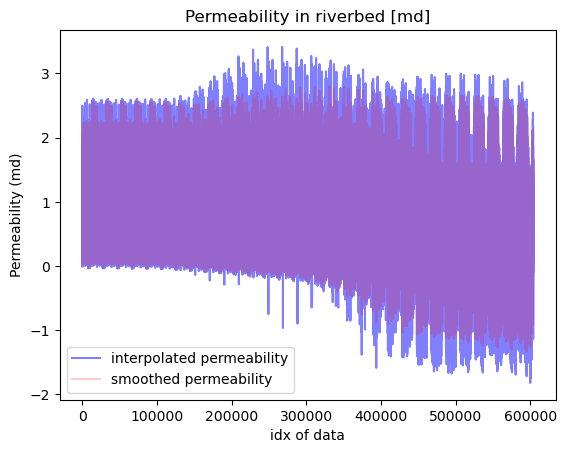

In [11]:
# plot the difference 

# Plot permeability in riverbed
fig = plt.figure()
# Plotting
#plt.scatter(interpolated_permeability_values, smoothed_permeability_values, alpha=0.5)
plt.plot(interpolated_permeability_values,color='blue',alpha=0.5,label='interpolated permeability')
plt.plot(smoothed_permeability_values,color='red',alpha=0.2,label='smoothed permeability')
plt.title('Permeability in riverbed [md]')
plt.ylabel('Permeability (md)')
plt.xlabel('idx of data')
plt.legend()
plt.show() 

## option1: assign new permeability to all layers under riverbed

In [8]:
# Convert log10perm_md in CSV into m^2
conversion_factor = 1.05e-12  #from md to m^2: 9.869233e-16   #convert from K[m/d] to k[m^2]: 1.05e-12

# Add interpolated values to centr_df
centroid_df.loc[centroid_df['river_idx']==True,'perm_value'] = 10**interpolated_permeability_values*conversion_factor

# Original perm data for different layers (XY), Z is 10 times smaller for layer <= 9
perm_list = {
    1: 7.368421e-09, 2: 1.052632e-10, 3: 1.052632e-12, 4: 4.210526e-11, 
    5: 1.052632e-12, 6: 1.052632e-12, 9: 1.052632e-15, 10: 4.65e-13
}

# Assign perm value from perm_list to all cells
for mat_id, perm_val in perm_list.items():
    centroid_df.loc[(centroid_df['river_idx']==False) & (centroid_df['mat_ids'] == mat_id), 'perm_value'] = perm_val

# Assign default perm value for NaN entries in perm_value where mat_ids == 10 and river_idx == True
#centroid_df.loc[(centroid_df['mat_ids'] == 10) & (centroid_df['river_idx'] == True) & centroid_df['perm_value'].isna(), 'perm_value'] = perm_list[10]

# Print the first few rows to verify
print(centroid_df.head())

               x              y           z         dem          cc  \
0  558454.229256  136693.840000  233.104122  228.606293  168.256302   
1  580508.238583  150448.245059  111.022571  111.108299  111.052498   
2  559932.654108  134754.205486  220.522968  214.780502  167.023102   
3  580575.455244  151015.296124  111.158507  110.878098  110.878098   
4  580653.188092  150675.546719  111.115299  110.869904  110.869904   

           tf          re         rlm         ra         ba  layer_ids  \
0  168.256302  168.256302   82.822807  82.822807  82.822807          1   
1  111.108299  109.727997  103.885201  31.682840  31.682840          1   
2  167.023102  167.023102   74.528709  48.215752 -16.753330          1   
3  110.878098  109.727997  103.776199  36.040798  36.040798          1   
4  110.869904  109.727997  103.723503  34.346680  34.346680          1   

   mat_ids  river_idx    perm_value  
0        1      False  7.368421e-09  
1       10       True  1.419444e-12  
2        1    

In [9]:
# apply filtering to data in alluvium layer
cutoff_perm = 1e-11

perm_old_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# Apply cutoff to the perm_value column
cutoff_value = 1e-11
centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] = \
    np.where(centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] > cutoff_perm,
             cutoff_perm,
             centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'])

perm_new_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# check the perm data in old alluvium and new alluvium layers
print('old alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_old_alluvium),np.max(perm_old_alluvium)))
print('new alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_new_alluvium),np.max(perm_new_alluvium)))

old alluvium data: min value: 9.470845151277634e-13, max value: 4.262981487682372e-10
new alluvium data: min value: 9.470845151277634e-13, max value: 1e-11


## option2: assign new permeability only to alluvium layer(ID=10)

In [12]:
# Convert log10perm_md in CSV into m^2
conversion_factor = 1.05e-12  #from md to m^2: 9.869233e-16   #convert from K[m/d] to k[m^2]: 1.05e-12

# Add interpolated values to centr_df
centroid_df.loc[centroid_df['river_idx']==True,'perm_value'] = 10**interpolated_permeability_values*conversion_factor

# Original perm data for different layers (XY), Z is 10 times smaller for layer <= 9
perm_list = {
    1: 7.368421e-09, 2: 1.052632e-10, 3: 1.052632e-12, 4: 4.210526e-11, 
    5: 1.052632e-12, 6: 1.052632e-12, 9: 1.052632e-15, 10: 4.65e-13
}

mat_new_id = [1, 2, 3, 4, 5, 6, 9]
    
# Assign perm value from perm_list to all cells
for mat_id, perm_val in perm_list.items():
    centroid_df.loc[(centroid_df['river_idx']==False) & (centroid_df['mat_ids'] == mat_id), 'perm_value'] = perm_val
    if mat_id in mat_new_id:
        centroid_df.loc[(centroid_df['river_idx']==True) & (centroid_df['mat_ids'] == mat_id), 'perm_value'] = perm_val
    
# Assign default perm value for NaN entries in perm_value where mat_ids == 10 and river_idx == True
#centroid_df.loc[(centroid_df['mat_ids'] == 10) & (centroid_df['river_idx'] == True) & centroid_df['perm_value'].isna(), 'perm_value'] = perm_list[10]

# Print the first few rows to verify
print(centroid_df.head())

               x              y           z         dem          cc  \
0  558454.229256  136693.840000  233.104122  228.606293  168.256302   
1  580508.238583  150448.245059  111.022571  111.108299  111.052498   
2  559932.654108  134754.205486  220.522968  214.780502  167.023102   
3  580575.455244  151015.296124  111.158507  110.878098  110.878098   
4  580653.188092  150675.546719  111.115299  110.869904  110.869904   

           tf          re         rlm         ra         ba  layer_ids  \
0  168.256302  168.256302   82.822807  82.822807  82.822807          1   
1  111.108299  109.727997  103.885201  31.682840  31.682840          1   
2  167.023102  167.023102   74.528709  48.215752 -16.753330          1   
3  110.878098  109.727997  103.776199  36.040798  36.040798          1   
4  110.869904  109.727997  103.723503  34.346680  34.346680          1   

   mat_ids  river_idx    perm_value  
0        1      False  7.368421e-09  
1       10       True  1.419444e-12  
2        1    

In [13]:
# apply filtering to data in alluvium layer
cutoff_perm = 1e-11

perm_old_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# Apply cutoff to the perm_value column
cutoff_value = 1e-11
centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] = \
    np.where(centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] > cutoff_perm,
             cutoff_perm,
             centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'])

perm_new_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# check the perm data in old alluvium and new alluvium layers
print('old alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_old_alluvium),np.max(perm_old_alluvium)))
print('new alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_new_alluvium),np.max(perm_new_alluvium)))

old alluvium data: min value: 9.470845072562483e-13, max value: 4.2629814872717076e-10
new alluvium data: min value: 9.470845072562483e-13, max value: 1e-11


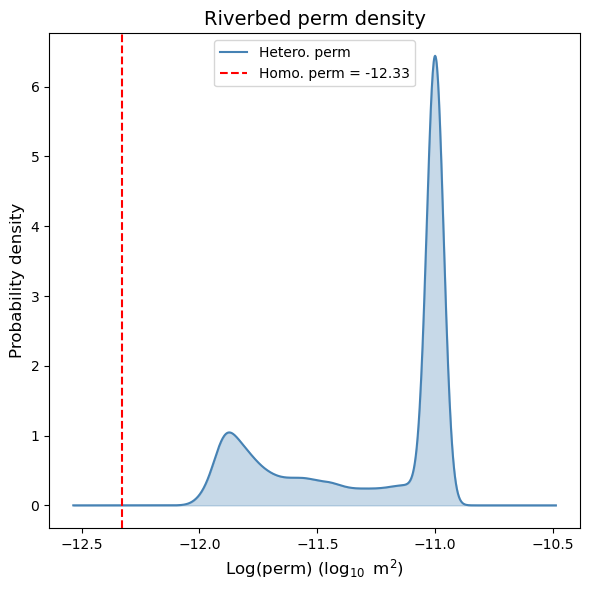

In [22]:
np.log10(perm_new_alluvium).plot.density(figsize=(6, 6), color='steelblue',
                                        label = 'Hetero. perm')   # pandas built-in KDE
# Get current axes and fill under the KDE curve
ax = plt.gca()
x, y = ax.lines[0].get_xdata(), ax.lines[0].get_ydata()
ax.fill_between(x, y, alpha=0.3, color='steelblue')

# Add vertical line at a constant x value (e.g. mean stage)
threshold = -12.33   # adjust to your value
ax.axvline(threshold, color='red', linestyle='--', linewidth=1.5, label=f'Homo. perm = {threshold}')

ax.set_xlabel(r"Log(perm) $(\log_{10}$ m$^2)$", fontsize=12)
ax.set_ylabel("Probability density", fontsize=12)
ax.set_title("Riverbed perm density", fontsize=14)
ax.legend()
plt.tight_layout()

fig = plt.gcf()
fig.savefig('../figures/riverbed_perm_density.jpg', dpi=300, bbox_inches='tight')
plt.show()

## option3: assign new permeability to all riverbed layers, except basalt (ID=9)

In [12]:
# Convert log10perm_md in CSV into m^2
conversion_factor = 1.05e-12  #from md to m^2: 9.869233e-16   #convert from K[m/d] to k[m^2]: 1.05e-12

# Add interpolated values to centr_df
centroid_df.loc[centroid_df['river_idx']==True,'perm_value'] = 10**interpolated_permeability_values*conversion_factor

# Original perm data for different layers (XY), Z is 10 times smaller for layer <= 9
perm_list = {
    1: 7.368421e-09, 2: 1.052632e-10, 3: 1.052632e-12, 4: 4.210526e-11, 
    5: 1.052632e-12, 6: 1.052632e-12, 9: 1.052632e-15, 10: 4.65e-13
}

mat_new_id = [9]
    
# Assign perm value from perm_list to all cells
for mat_id, perm_val in perm_list.items():
    centroid_df.loc[(centroid_df['river_idx']==False) & (centroid_df['mat_ids'] == mat_id), 'perm_value'] = perm_val
    if mat_id in mat_new_id:
        centroid_df.loc[(centroid_df['river_idx']==True) & (centroid_df['mat_ids'] == mat_id), 'perm_value'] = perm_val
    
# Assign default perm value for NaN entries in perm_value where mat_ids == 10 and river_idx == True
#centroid_df.loc[(centroid_df['mat_ids'] == 10) & (centroid_df['river_idx'] == True) & centroid_df['perm_value'].isna(), 'perm_value'] = perm_list[10]

# Print the first few rows to verify
print(centroid_df.head())

               x              y           z         dem          cc  \
0  558454.229256  136693.840000  233.104122  228.606293  168.256302   
1  580508.238583  150448.245059  111.022571  111.108299  111.052498   
2  559932.654108  134754.205486  220.522968  214.780502  167.023102   
3  580575.455244  151015.296124  111.158507  110.878098  110.878098   
4  580653.188092  150675.546719  111.115299  110.869904  110.869904   

           tf          re         rlm         ra         ba  layer_ids  \
0  168.256302  168.256302   82.822807  82.822807  82.822807          1   
1  111.108299  109.727997  103.885201  31.682840  31.682840          1   
2  167.023102  167.023102   74.528709  48.215752 -16.753330          1   
3  110.878098  109.727997  103.776199  36.040798  36.040798          1   
4  110.869904  109.727997  103.723503  34.346680  34.346680          1   

   mat_ids  river_idx    perm_value  
0        1      False  7.368421e-09  
1       10       True  1.419444e-12  
2        1    

In [13]:
# apply filtering to data in alluvium layer
cutoff_perm = 1e-11

perm_old_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# Apply cutoff to the perm_value column
cutoff_value = 1e-11
centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] = \
    np.where(centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] > cutoff_perm,
             cutoff_perm,
             centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'])

perm_new_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# check the perm data in old alluvium and new alluvium layers
print('old alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_old_alluvium),np.max(perm_old_alluvium)))
print('new alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_new_alluvium),np.max(perm_new_alluvium)))

old alluvium data: min value: 9.470845151277634e-13, max value: 4.262981487682372e-10
new alluvium data: min value: 9.470845151277634e-13, max value: 1e-11


## end of options

In [13]:
# check if any NaN in perm_value unassigned.
centroid_df['perm_value'].isnull().sum().sum()

0

In [15]:
cell_ID = np.array(centroid_df.index.tolist(), dtype='i4') + 1  # starting from 1, rather than 0
    
# Find the corresponding perm_values
permX = centroid_df['perm_value'].tolist()
permY = permX

# Conditional value for permZ based on 'mat_ids' column, only alluvium layer does not change
permZ = [val if mat_ids==10 else 0.1 * val for val, mat_ids in zip(permX, centroid_df['mat_ids'])]

In [16]:
# File path to save the .h5 data
file_path = '/global/homes/z/zc727/HFR/data/'

# Define the output HDF5 filename
output_file = f'{file_path}perm_data_all_except_basalt.h5'

# Remove the file if it exists to avoid file open conflicts automatically
if os.path.exists(output_file):
    os.remove(output_file)

# Save to HDF5 using h5py
with File(output_file, 'w') as h5file:
    h5file.create_dataset('Cell Ids', data=np.array(cell_ID, dtype='i4'))
    h5file.create_dataset('perm_meanX', data=np.array(permX, dtype='f8'))
    h5file.create_dataset('perm_meanY', data=np.array(permY, dtype='f8'))
    h5file.create_dataset('perm_meanZ', data=np.array(permZ, dtype='f8'))

print(f'Saved data to {output_file}')

Saved data to /global/homes/z/zc727/HFR/data/perm_data_all_except_basalt.h5


In [14]:
#with open("/global/homes/z/zc727/HFR/data/centroid_perm_df.p", 'wb') as f:
#    pickle.dump(centroid_df, f, protocol=-1)

In [17]:
# compare the cell-wise permeability value with old method
centroid_df_old = centroid_df[centroid_df['river_idx']==True].copy()

# Assign perm value from perm_list to cells where river_idx is False based on their mat_ids
for mat_id, perm_val in perm_list.items():
    centroid_df_old.loc[centroid_df_old['mat_ids'] == mat_id, 'perm_value'] = perm_val

centroid_df_new = centroid_df[centroid_df['river_idx']==True].copy()

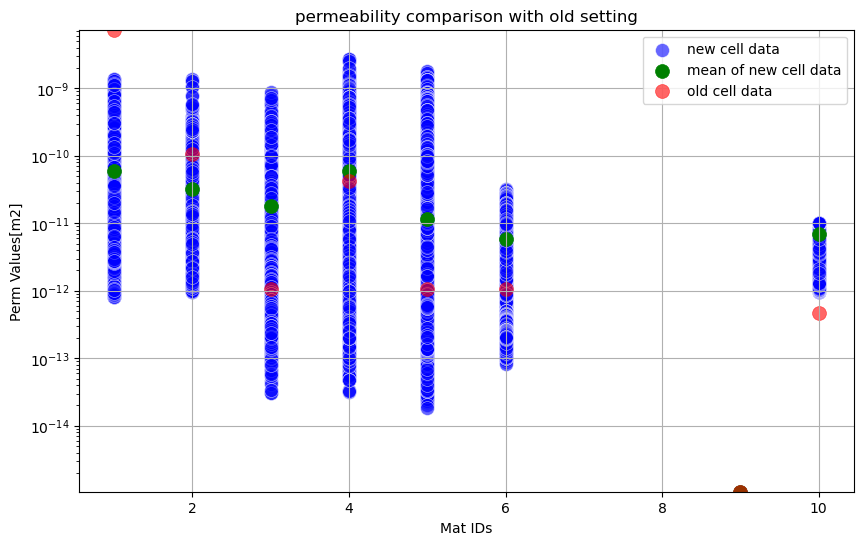

In [18]:
# Scatter plot
plt.figure(figsize=(10, 6))

# original perm data
perm_list_ids = list(perm_list.keys())
perm_list_values = list(perm_list.values())

# Initialize lists for mean values and their IDs
perm_mean_values = []
perm_mean_ids = []

# Calculate mean permeability value for each mat_id
for mat_id in perm_list.keys():
    ids = mat_id
    perm_mean = np.mean(centroid_df_new.loc[centroid_df_new['mat_ids'] == mat_id, 'perm_value'])
    
    perm_mean_ids.append(ids)
    perm_mean_values.append(perm_mean)

# Plot perm_values as scatter points with respect to mat_ids
plt.scatter(centroid_df_new['mat_ids'], centroid_df_new['perm_value'], 
            color='blue', s=100, alpha=0.6, edgecolors='w', linewidth=0.5)

plt.scatter(perm_mean_ids,perm_mean_values,color='green',s=100,linewidth=0.5)

plt.scatter(perm_list_ids,perm_list_values,color='red',s=100,alpha=0.6,linewidth=0.5)

# Adding title and labels
plt.title('permeability comparison with old setting')
plt.xlabel('Mat IDs')
plt.ylabel('Perm Values[m2]')
plt.yscale('log')

all_perm_values = np.concatenate((centroid_df_new['perm_value'].values,perm_list_values))
y_min = np.min(all_perm_values)
y_max = np.max(all_perm_values)

plt.ylim(y_min, y_max)

# Customize tick marks
#plt.xticks(rotation=45)
#plt.yticks(np.arange(0, 0.6, step=0.1))

# Add grid lines
plt.grid(True)

plt.legend(['new cell data','mean of new cell data','old cell data'])

# Show plot
plt.show()

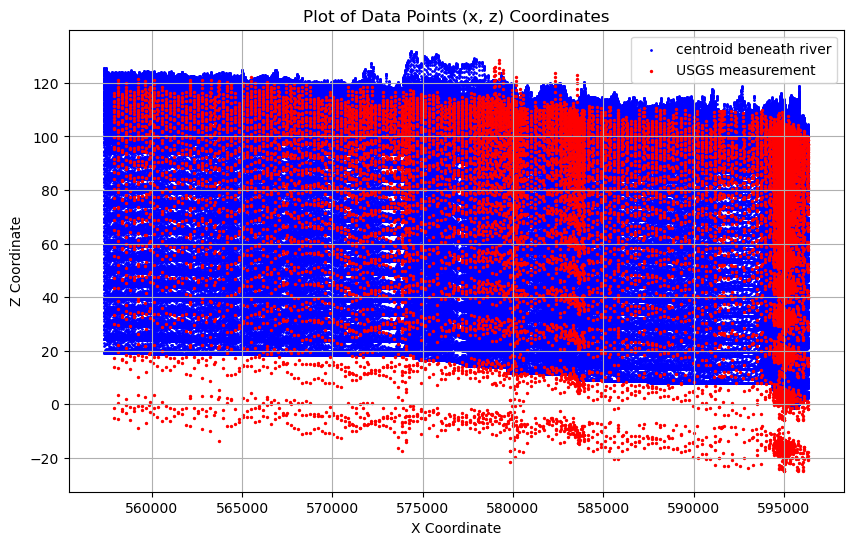

In [61]:
# Plotting (x, z) coordinates
fig, ax = plt.subplots(figsize=(10, 6))

# Scatter plot
ax.scatter(centroid_df_new['x'], centroid_df_new['z'], color='blue', s=1, label='centroid beneath river')
ax.scatter(perm_df['X_ESRI_102349'],perm_df['elevation_m'], color='red', s=2, label='USGS measurement')

# Label and customize the plot
ax.set_title('Plot of Data Points (x, z) Coordinates')
ax.set_xlabel('X Coordinate')
ax.set_ylabel('Z Coordinate')
ax.legend()

plt.grid(True)
plt.show()

## double check if the output file has the right data writing

total number of uniqe permeability: 97385


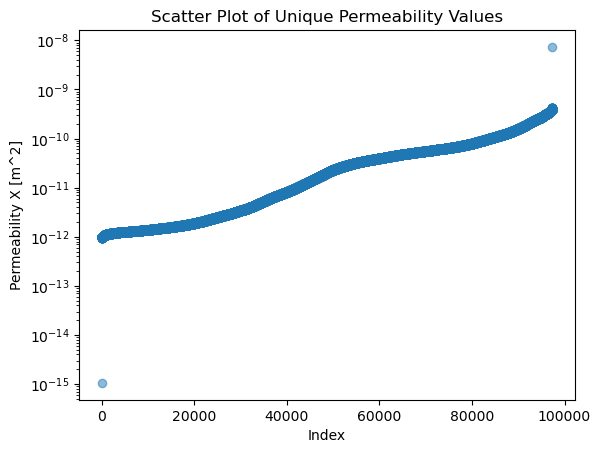

In [36]:
filepath = '/global/homes/z/zc727/HFR/data/perm_data_only_alluvium.h5'
    
# Open the file in read mode
with h5.File(filepath, 'r') as input_file:
    # Read the dataset
    permeability_x = input_file['perm_meanX'][:]

# Calculate the total number of unique permeability values
unique_permeability_x = np.unique(permeability_x)

print(f'total number of uniqe permeability: {len(unique_permeability_x)}')

# Plotting the unique permeability values
plt.scatter(range(len(unique_permeability_x)), unique_permeability_x, alpha=0.5)
plt.yscale('log')
plt.title('Scatter Plot of Unique Permeability Values')
plt.xlabel('Index')
plt.ylabel('Permeability X [m^2]')

# Show the plot
plt.show()

## plot perm distribution

In [23]:
# filepath = '/global/homes/z/zc727/HFR/data/perm_data_only_alluvium.h5'
filepath = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/data/perm_data_only_alluvium_smoothed_cutoff.h5'
    
# Open the file in read mode
perm_file = h5.File(filepath, "r")

In [28]:
perm_file.visititems(print_structure)

Cell Ids
perm_meanX
perm_meanY
perm_meanZ


total number of uniqe permeability: 97385


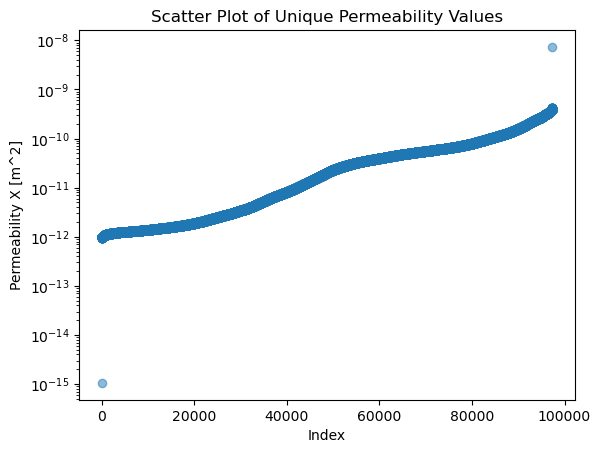

In [ ]:
with h5.File(filepath, 'r') as input_file:
    # Read the dataset
    permeability_x = input_file['perm_meanX'][:]

# Calculate the total number of unique permeability values
unique_permeability_x = np.unique(permeability_x)

print(f'total number of uniqe permeability: {len(unique_permeability_x)}')

# Plotting the unique permeability values
plt.scatter(range(len(unique_permeability_x)), unique_permeability_x, alpha=0.5)
plt.yscale('log')
plt.title('Scatter Plot of Unique Permeability Values')
plt.xlabel('Index')
plt.ylabel('Permeability X [m^2]')

# Show the plot
plt.show()